# 11 — Part 2 modelling (training years 2007–2014 only)
**Plan:** [`docs/part2_plan.md`](../docs/part2_plan.md) §6.

**Rules**
- Only **2007–2014** is used. The 2015–2018 test years stay untouched until notebook 12.
- Cross-validation: **5 folds × 3 repeats** (15 splits), with each NHANES sampling cluster kept inside one fold. People sampled from the
  same area aren't independent, so splitting them across folds would make results look better than they are.
- Every candidate is compared with the official baseline **on the same folds** and **at the baseline's referral rate in that fold**.
- Selection: the simplest model within one standard error of the best (as in Part 1).

In [1]:
import sys, json, platform
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score

from src.data import PROJECT_ROOT
from src.models import logistic, gradient_boosting, threshold_for_rate
from src.part2_data import load
from src.part2_models import TARGETS, MODEL_KINDS, CHAIN_FEATURE, cv_splits, add_diabetes_risk, evaluate_fold

sns.set_theme(style="whitegrid")
train = load("train")
for name, t in TARGETS.items():
    rows = train[train[t["target"]].notna()]
    print(f"{name:9s}: {len(rows):,} adults, {int(rows[t['target']].sum()):,} cases ({rows[t['target']].mean():.1%}), "
          f"{rows.cluster.nunique()} sampling clusters")

diabetes : 18,630 adults, 697 cases (3.7%), 124 sampling clusters
ckd      : 20,326 adults, 3,440 cases (16.9%), 124 sampling clusters


## 1. Cross-validated comparison with the official baselines

In [2]:
def run_cv(name, kinds, chain=False):
    t = TARGETS[name]
    feats = t["features"] + ([CHAIN_FEATURE] if chain else [])
    rows = []
    for i, (tr, va) in enumerate(cv_splits(train, t["target"])):
        fit, val = train.loc[tr], train.loc[va]
        if chain:
            # Diabetes risk is learned without the validation fold: validation people get a model fitted on everyone
            # else; training people get out-of-fold risks (see src/part2_models.py)
            fit_all, val = add_diabetes_risk(train.loc[~train.index.isin(va)], val)
            fit = fit_all.loc[tr]
        for kind_name, kind in kinds.items():
            model = kind(feats).fit(fit[feats], fit[t["target"]])
            scores = model.predict_proba(val[feats])[:, 1]
            m = evaluate_fold(scores, val[t["rule"]].to_numpy(), val[t["rule_score"]].to_numpy(), val[t["target"]].to_numpy())
            rows.append({"model": kind_name + (" + diabetes risk" if chain else ""), "fold": i, **m})
    return pd.DataFrame(rows)

def summarise(res):
    res = res.assign(diff=res.sens_at_rule_rate - res.rule_sens)
    g = res.groupby("model")
    out = pd.DataFrame({
        "cases caught (model)": g.sens_at_rule_rate.mean(), "cases caught (baseline)": g.rule_sens.mean(),
        "difference": g["diff"].mean(), "SE of difference": g["diff"].std() / np.sqrt(g.size()),
        "folds model better": g["diff"].apply(lambda d: (d > 0).mean()),
        "ROC-AUC": g.roc_auc.mean(), "baseline ROC-AUC": g.rule_roc_auc.mean(), "PR-AUC": g.pr_auc.mean(),
        "baseline refers": g.rule_rate.mean(),
    })
    return out.round(3)

cv_diab = run_cv("diabetes", MODEL_KINDS)
summarise(cv_diab)

,cases caught (model),cases caught (baseline),difference,SE of difference,folds model better,ROC-AUC,baseline ROC-AUC,PR-AUC,baseline refers
model,,,,,,,,,
Gradient boosting,0.817,0.822,-0.005,0.007,0.467,0.789,0.774,0.128,0.397
Logistic regression,0.836,0.822,0.014,0.006,0.600,0.793,0.774,0.133,0.397


**Diabetes:** at the CDC/ADA score's referral rate (40 %), logistic regression catches **83.6 %** of undiagnosed diabetes and the score
catches **82.2 %**. That's **+1.4 points** (SE 0.6), better in 60 % of folds: a small but fairly consistent edge. Its ROC-AUC is 0.793 vs the
score's 0.774. Gradient boosting does slightly *worse* than the score. With only 697 cases, a flexible model mostly fits noise.
PR-AUC is low (0.13) for every method, because only 3.7 % have undiagnosed diabetes. Most people referred for HbA1c will test negative,
whatever method is used.

In [3]:
cv_ckd = pd.concat([run_cv("ckd", MODEL_KINDS), run_cv("ckd", MODEL_KINDS, chain=True)], ignore_index=True)
summarise(cv_ckd)

,cases caught (model),cases caught (baseline),difference,SE of difference,folds model better,ROC-AUC,baseline ROC-AUC,PR-AUC,baseline refers
model,,,,,,,,,
Gradient boosting,0.816,0.778,0.038,0.003,1.000,0.802,0.691,0.504,0.461
Gradient boosting + diabetes risk,0.816,0.778,0.038,0.003,1.000,0.801,0.691,0.503,0.461
Logistic regression,0.804,0.778,0.027,0.003,0.933,0.785,0.691,0.480,0.461
Logistic regression + diabetes risk,0.804,0.778,0.027,0.003,0.933,0.785,0.691,0.479,0.461


**Kidney markers:** both models beat the KDIGO priority groups clearly. Gradient boosting catches **81.6 %** vs **77.8 %**, which is
**+3.8 points** (SE 0.3), better in **every one of the 15 folds**. Logistic regression adds +2.7 points. ROC-AUC rises from **0.69** (KDIGO) to
**0.80**. The KDIGO groups are a yes/no rule, so they can't rank people within each group. The models can, mainly by using age.
**Adding the predicted diabetes risk changes nothing** (identical rows ±0.001). Section 3 explains why.

## 2. Model selection (one-standard-error rule)
Primary metric: cases caught at the baseline's referral rate. Simplicity order: logistic regression → gradient boosting, and without the
diabetes-risk input before with it.

In [4]:
def choose(res, order):
    stats = res.groupby("model").sens_at_rule_rate.agg(["mean", "std", "count"])
    stats["se"] = stats["std"] / np.sqrt(stats["count"])
    best = stats["mean"].idxmax()
    ok = stats.index[stats["mean"] >= stats.loc[best, "mean"] - stats.loc[best, "se"]]
    return best, list(ok), next(m for m in order if m in ok)

chosen = {}
for name, res, order in [
    ("diabetes", cv_diab, ["Logistic regression", "Gradient boosting"]),
    ("ckd", cv_ckd, ["Logistic regression", "Logistic regression + diabetes risk", "Gradient boosting",
                     "Gradient boosting + diabetes risk"]),
]:
    best, ok, pick = choose(res, order)
    chosen[name] = pick
    print(f"{name:9s} best: {best:40s} within 1 SE: {ok}\n          -> chosen: {pick}\n")

diabetes  best: Logistic regression                      within 1 SE: ['Logistic regression']
          -> chosen: Logistic regression

ckd       best: Gradient boosting                        within 1 SE: ['Gradient boosting', 'Gradient boosting + diabetes risk']
          -> chosen: Gradient boosting



- **Diabetes → logistic regression.** It is both the best and the simplest.
- **Kidney → gradient boosting.** It beats logistic regression by more than one standard error, so the extra complexity is justified here.
  That fits the audit: kidney risk rises non-linearly with age, and low diastolic BP in older adults goes the "wrong" way for a straight-line model.
- The diabetes-risk input is **not chosen**: it was within one SE of the best, but the simpler model without it ranks first in the order.

## 3. Does diabetes risk help find kidney disease? (interconnection, training years)
Paired comparison, on the same folds, of each CKD model with and without the predicted diabetes risk as an extra input. This is a preview; the
pre-registered test (§7.3.2) happens on 2015–2018.

In [5]:
wide = cv_ckd.pivot(index="fold", columns="model", values="roc_auc")
for base in ["Logistic regression", "Gradient boosting"]:
    d = wide[base + " + diabetes risk"] - wide[base]
    print(f"{base:20s}: ROC-AUC change with diabetes risk {d.mean():+.4f} (SE {d.std() / np.sqrt(len(d)):.4f}), "
          f"better in {(d > 0).mean():.0%} of folds")

Logistic regression : ROC-AUC change with diabetes risk -0.0002 (SE 0.0002), better in 33% of folds
Gradient boosting   : ROC-AUC change with diabetes risk -0.0007 (SE 0.0006), better in 33% of folds


**A negative but instructive result.** Adding predicted diabetes risk doesn't help the kidney model at all (ROC-AUC change −0.0002 and
−0.0007, better in only a third of folds).

**Why?** The predicted diabetes risk is calculated *from the same routine inputs* the kidney model already sees (age, waist, BP …).
It contains no information the kidney model doesn't already have. It just repackages it.

So the conditions really are connected (notebook 10: undiagnosed diabetes more than doubles the rate of kidney markers), but **a prediction
can't carry that connection**. Only the **actual HbA1c result** could, because it is new information from a blood test. That suggests a better
interconnected design: *test HbA1c first, then use the result to decide about the kidney panel*. That idea is for notebook 12 (exploratory) and
the report. The pre-registered chain test (§7.3.2) will still be run on 2015–2018 as planned.

## 4. Calibration of the chosen models (out-of-fold, training years)

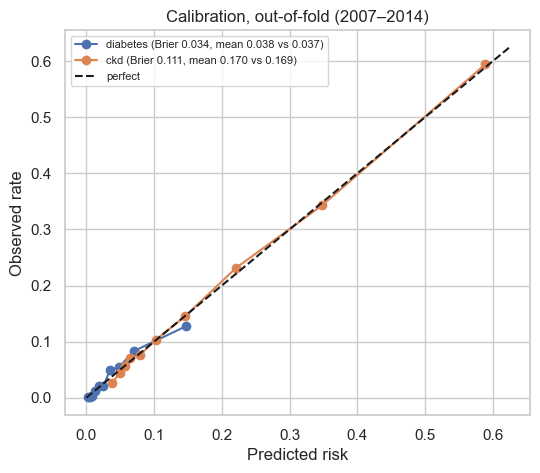

In [6]:
def factory(model_name):
    return gradient_boosting if model_name.startswith("Gradient") else logistic

def oof_predictions(name):
    t = TARGETS[name]
    use_chain = chosen[name].endswith("diabetes risk")
    feats = t["features"] + ([CHAIN_FEATURE] if use_chain else [])
    rows = train[train[t["target"]].notna()]
    p = pd.Series(np.nan, index=rows.index)
    for tr, va in cv_splits(train, t["target"], n_repeats=1):
        fit, val = train.loc[tr], train.loc[va]
        if use_chain:
            fit, val = add_diabetes_risk(train.loc[~train.index.isin(va)], val)
            fit = fit.loc[fit.index.isin(tr)]
        p[va] = factory(chosen[name])(feats).fit(fit[feats], fit[t["target"]]).predict_proba(val[feats])[:, 1]
    return rows[t["target"]], p

oof = {name: oof_predictions(name) for name in TARGETS}
fig, ax = plt.subplots(figsize=(6, 5))
for name, (y, p) in oof.items():
    fp, mp = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax.plot(mp, fp, "o-", label=f"{name} (Brier {brier_score_loss(y, p):.3f}, mean {p.mean():.3f} vs {y.mean():.3f})")
lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, lim], [0, lim], "k--", label="perfect")
ax.set_xlabel("Predicted risk"); ax.set_ylabel("Observed rate"); ax.legend(fontsize=8)
ax.set_title("Calibration, out-of-fold (2007–2014)")
plt.show()

Both models are **very well calibrated** in the training years. Mean predicted risk is 3.8 % vs 3.7 % observed (diabetes), and 17.0 %
vs 16.9 % (kidney), with points close to the diagonal across the range. That's unlike Part 1, where the model moved to a different population.
Here, training and use are both NHANES. Notebook 12 checks whether calibration holds in the later years.

*Note on thresholds:* both baselines already catch about 80 % of cases at their own referral rate. So the "high-sensitivity" (≥ 80 %)
threshold refers **fewer** people than the matched-rate threshold (36 % vs 40 % for diabetes). For these targets it's the *more selective*
option, not the broader one.

## 5. Thresholds (from out-of-fold training predictions)
- **Matched-rate:** refers the same share as the official baseline did in 2007–2014.
- **High-sensitivity:** the highest cut-off that still catches ≥ 80 % of cases in training.

In [7]:
def high_sens_threshold(y, p, target=0.80):
    order = np.sort(np.unique(p))[::-1]
    for t in order:
        if ((p >= t) & (y == 1)).sum() / (y == 1).sum() >= target:
            return float(t)

thresholds = {}
for name, (y, p) in oof.items():
    t = TARGETS[name]
    rate = train.loc[y.index, t["rule"]].mean()
    thresholds[name] = {"matched_rate": threshold_for_rate(p.to_numpy(), rate), "high_sensitivity": high_sens_threshold(y.to_numpy(), p.to_numpy())}
    for label, th in thresholds[name].items():
        ref = p >= th
        print(f"{name:9s} {label:17s} {th:.4f}: refers {ref.mean():.1%}, catches {(ref & (y == 1)).sum() / y.sum():.1%}")
    print(f"{'':9s} baseline ({t['rule']}) refers {rate:.1%}\n")

diabetes  matched_rate      0.0298: refers 39.7%, catches 83.6%
diabetes  high_sensitivity  0.0337: refers 36.1%, catches 80.1%
          baseline (CDCHighRisk) refers 39.7%



ckd       matched_rate      0.0995: refers 46.1%, catches 81.3%
ckd       high_sensitivity  0.1066: refers 43.8%, catches 80.0%
          baseline (KDIGOPriority) refers 46.1%



## 6. Fit the chosen models on all of 2007–2014 and save them

In [8]:
out_dir = PROJECT_ROOT / "models" / "part2"
out_dir.mkdir(parents=True, exist_ok=True)
meta = {"sklearn_version": sklearn.__version__, "python_version": platform.python_version(),
        "trained_on": "NHANES 2007-2014 (src.part2_data, split == 'train')", "models": {}}

# The diabetes model is always saved: it is a target model and, if chosen, the first link of the kidney chain
d = TARGETS["diabetes"]
d_rows = train[train[d["target"]].notna()]
diabetes_model = factory(chosen["diabetes"])(d["features"]).fit(d_rows[d["features"]], d_rows[d["target"]])
joblib.dump(diabetes_model, out_dir / "diabetes.joblib")

k = TARGETS["ckd"]
k_chain = chosen["ckd"].endswith("diabetes risk")
k_feats = k["features"] + ([CHAIN_FEATURE] if k_chain else [])
k_rows = train[train[k["target"]].notna()].copy()
if k_chain:
    k_rows, _ = add_diabetes_risk(train, train.iloc[:1])     # out-of-fold diabetes risk for every training adult
    k_rows = k_rows[k_rows[k["target"]].notna()]
ckd_model = factory(chosen["ckd"])(k_feats).fit(k_rows[k_feats], k_rows[k["target"]])
joblib.dump(ckd_model, out_dir / "ckd.joblib")

cv_all = {"diabetes": cv_diab, "ckd": cv_ckd}
for name, feats, chain in [("diabetes", d["features"], False), ("ckd", k_feats, k_chain)]:
    r = cv_all[name][cv_all[name].model == chosen[name]]
    meta["models"][name] = {
        "file": f"models/part2/{name}.joblib", "config": chosen[name], "features": feats,
        "uses_diabetes_model": chain, "target": TARGETS[name]["target"], "baseline": TARGETS[name]["rule"],
        "thresholds": {k_: round(v, 5) for k_, v in thresholds[name].items()},
        "cv_mean": r[["roc_auc", "pr_auc", "sens_at_rule_rate", "rule_sens", "rule_roc_auc"]].mean().round(4).to_dict(),
    }
(out_dir / "metadata.json").write_text(json.dumps(meta, indent=2))
print(json.dumps({k_: {"config": v["config"], "thresholds": v["thresholds"], "cv_mean": v["cv_mean"]} for k_, v in meta["models"].items()}, indent=2))

{
  "diabetes": {
    "config": "Logistic regression",
    "thresholds": {
      "matched_rate": 0.02983,
      "high_sensitivity": 0.03366
    },
    "cv_mean": {
      "roc_auc": 0.7933,
      "pr_auc": 0.1327,
      "sens_at_rule_rate": 0.836,
      "rule_sens": 0.8221,
      "rule_roc_auc": 0.7739
    }
  },
  "ckd": {
    "config": "Gradient boosting",
    "thresholds": {
      "matched_rate": 0.09953,
      "high_sensitivity": 0.10655
    },
    "cv_mean": {
      "roc_auc": 0.8017,
      "pr_auc": 0.5043,
      "sens_at_rule_rate": 0.8157,
      "rule_sens": 0.7777,
      "rule_roc_auc": 0.6907
    }
  }
}


## 7. What did the models learn?

In [9]:
# Logistic regression: coefficient per standard deviation. Gradient boosting: permutation importance (drop in ROC-AUC).
tabs = {}
for name, model in [("diabetes", diabetes_model), ("ckd", ckd_model)]:
    feats = meta["models"][name]["features"]
    if hasattr(model[-1], "coef_"):
        tabs[name] = pd.Series(model[-1].coef_[0], index=model[:-1].get_feature_names_out())
    else:
        from sklearn.inspection import permutation_importance
        rows = train[train[TARGETS[name]["target"]].notna()]
        if name == "ckd" and k_chain:
            rows = k_rows
        sample = rows.sample(4000, random_state=0)
        imp = permutation_importance(model, sample[feats], sample[TARGETS[name]["target"]], scoring="roc_auc", n_repeats=5, random_state=0)
        tabs[name] = pd.Series(imp.importances_mean, index=feats)
pd.DataFrame(tabs).round(3).sort_values("diabetes", key=abs, ascending=False)

,diabetes,ckd
Age,0.649,0.104
Waist,0.400,0.004
FamilyHistoryDiabetes,0.304,0.001
BMI,0.260,0.012
SBP,0.208,0.028
GestationalDiabetes,0.185,-0.000
Male,0.170,0.005
PhysicallyActive,-0.098,0.003
CurrentSmoker,0.067,0.002
CVD,0.031,0.002


- **Diabetes (logistic regression, log-odds per SD):** **age** (0.65) and **waist** (0.40) dominate, followed by **family history** (0.30),
  BMI (0.26), systolic BP (0.21), gestational diabetes (0.19) and male sex (0.17). Physical activity is protective (−0.10). Waist carries more
  than BMI, which supports measuring waist at the visit.
- **Kidney (gradient boosting, drop in ROC-AUC when shuffled):** **age** is by far the most important (0.10). Next come systolic BP (0.03),
  diagnosed diabetes (0.025), BMI (0.012) and diastolic BP (0.008). This matches what drives CKD clinically: age, blood pressure and diabetes.
- Associations, not causes.

## 8. Summary and plan for Stage 4
**Provisional results (cross-validation, 2007–2014)**

| Target | Chosen model | Cases caught at baseline's rate | ROC-AUC |
|---|---|---|---|
| Undiagnosed diabetes | Logistic regression | 83.6 % vs CDC/ADA 82.2 % (+1.4) | 0.793 vs 0.774 |
| Undiagnosed kidney markers | Gradient boosting | 81.6 % vs KDIGO 77.8 % (+3.8) | 0.802 vs 0.691 |

1. **Diabetes:** a small edge over a strong official questionnaire. It may or may not survive the test years.
2. **Kidney:** a clear, consistent edge over the KDIGO priority groups, mainly by ranking people within them.
3. **Interconnection:** predicted diabetes risk adds nothing to the kidney model, because it is built from the same inputs. The connection
   between the conditions can only be exploited with *new* information, such as an actual HbA1c result.
4. Both models are well calibrated in the training years.

**Saved:** `models/part2/diabetes.joblib`, `models/part2/ckd.joblib` and `models/part2/metadata.json`, with features, thresholds and CV scores.

**Stage 4 (notebook 12):** a single evaluation on **2015–2018**: P1 and P2 with cluster-bootstrap CIs, the chain test, the combined
one-blood-draw policy, fairness by sex, age and race/ethnicity, survey weights, the eGFR-only sensitivity check, and, exploratory, an
"HbA1c first, then kidney" sequence.